In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay )

from IPython.display import display

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
DATA_DIR = PROJECT_ROOT / "data" / "processed"

SPLITS = ["stratified", "project_grouped"]
MODELS = ["tfidf", "semantic"]

print("Project directory:", PROJECT_ROOT)

Project directory: d:\uOttawa\Fall_26\CSI5187\project


In [4]:
comparison = pd.read_csv(RESULTS_DIR / "metrics" / "test_comparison.csv")

display(comparison.round(4))

# Present macro-F1 in a comparison table
f1_comparison = comparison.pivot(index="split", columns="model", values="macro_f1")

f1_comparison["MPNet - TF-IDF"] = (f1_comparison["semantic"] - f1_comparison["tfidf"])

print("\nMacro-F1 Comparison:")
display(f1_comparison.round(4))

,split,model,accuracy,macro_f1
0,stratified,tfidf,0.7301,0.7180
1,stratified,semantic,0.7244,0.7214
2,project_grouped,tfidf,0.7910,0.7839
3,project_grouped,semantic,0.7373,0.7353



Macro-F1 Comparison:


model,semantic,tfidf,MPNet - TF-IDF
split,,,
project_grouped,0.7353,0.7839,-0.0486
stratified,0.7214,0.7180,0.0034


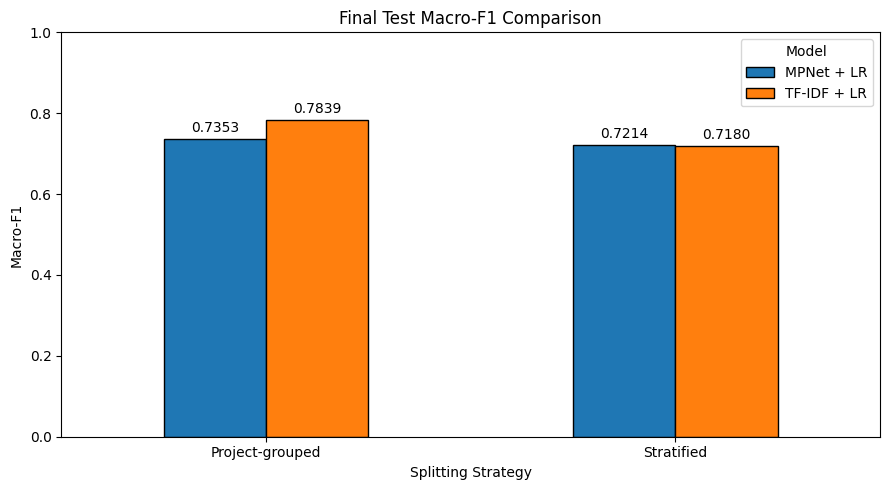

In [5]:
plot_data = comparison.pivot(index="split", columns="model", values="macro_f1")

plot_data = plot_data.rename(
    columns={
        "tfidf": "TF-IDF + LR",
        "semantic": "MPNet + LR"
    },
    index={
        "stratified": "Stratified",
        "project_grouped": "Project-grouped"
    }
)

ax = plot_data.plot(kind="bar", figsize=(9, 5), edgecolor="black", rot=0)

ax.set_title("Final Test Macro-F1 Comparison")
ax.set_xlabel("Splitting Strategy")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [6]:
baseline_results = []

for split_type in SPLITS:

    test_df = pd.read_csv(DATA_DIR / split_type / "test.csv")

    y_true = test_df["label"]
    y_pred = np.zeros(len(y_true), dtype=int)

    baseline_results.append({
        "split": split_type,
        "model": "majority_baseline",
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score( y_true, y_pred, average="macro", zero_division=0)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(4))

,split,model,accuracy,macro_f1
0,stratified,majority_baseline,0.5682,0.3623
1,project_grouped,majority_baseline,0.5678,0.3622


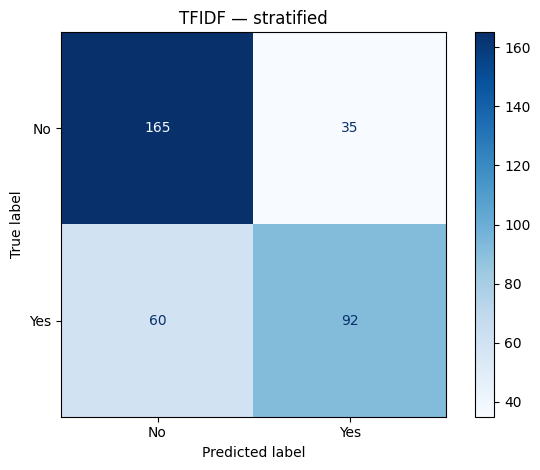

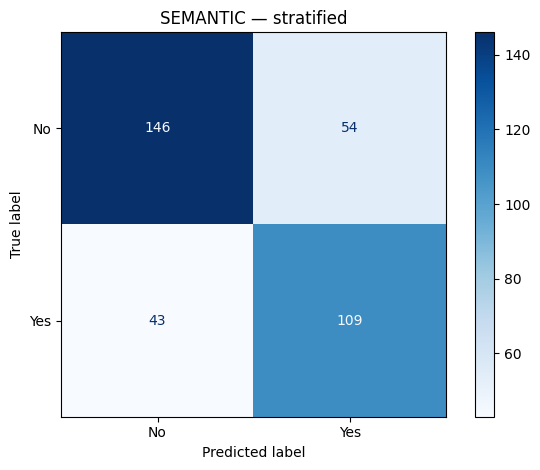

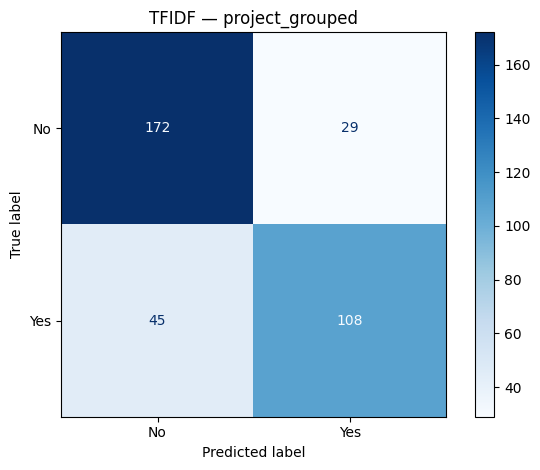

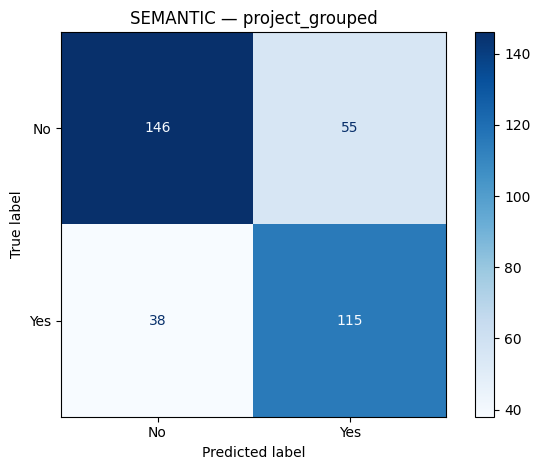

In [7]:
for split_type in SPLITS:

    for model_type in MODELS:

        predictions = pd.read_csv(RESULTS_DIR / "predictions" / split_type / f"{model_type}_predictions.csv")
        cm = confusion_matrix(predictions["label"], predictions["prediction"], labels=[0, 1])

        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])

        disp.plot(cmap="Blues", values_format="d")

        plt.title(f"{model_type.upper()} — {split_type}")

        plt.tight_layout()
        plt.show()

In [8]:
positive_results = []

for split_type in SPLITS:

    for model_type in MODELS:

        df_pred = pd.read_csv(RESULTS_DIR / "predictions" / split_type / f"{model_type}_predictions.csv")

        positive_results.append({"split": split_type, "model": model_type,
            "precision_yes": precision_score( df_pred["label"],df_pred["prediction"],pos_label=1, zero_division=0),
            "recall_yes": recall_score(df_pred["label"],df_pred["prediction"],pos_label=1,zero_division=0),
            "f1_yes": f1_score(df_pred["label"],df_pred["prediction"],pos_label=1, zero_division=0)
        })

positive_df = pd.DataFrame(positive_results)

display(positive_df.round(4))

,split,model,precision_yes,recall_yes,f1_yes
0,stratified,tfidf,0.7244,0.6053,0.6595
1,stratified,semantic,0.6687,0.7171,0.6921
2,project_grouped,tfidf,0.7883,0.7059,0.7448
3,project_grouped,semantic,0.6765,0.7516,0.7121


In [9]:
for split_type in SPLITS:

    disagreements = pd.read_csv(RESULTS_DIR / "error_analysis" / split_type / "model_disagreements.csv")

    print(f"\nSplit: {split_type}")
    print("Total disagreements:", len(disagreements))

    sample = disagreements.sample(n=min(15, len(disagreements)), random_state=42)

    display(sample[["bodyText","label","tfidf_prediction","semantic_prediction"]])


Split: stratified
Total disagreements: 110


,bodyText,label,tfidf_prediction,semantic_prediction
78,This is not correct. It must be either https o...,0,1,0
10,Please use AssertJ,1,0,1
4,Suggested change ...,1,1,0
84,surround everything in a try catch to trace an...,0,0,1
64,Suggested change ...,1,1,0
68,I don't think these annotations are needed - t...,1,1,0
30,"I think, that also unsuspendMember below shoul...",0,0,1
45,"you could flip this comparison, as that makes ...",1,0,1
96,Would it hurt to instead initialise the proper...,0,1,0
11,This doesn't seem to be used.,1,0,1



Split: project_grouped
Total disagreements: 83


,bodyText,label,tfidf_prediction,semantic_prediction
30,Ditto,0,1,0
0,@gemmellr I saw an email from you asking about...,0,0,1
22,@martinezmatias a rotten assertion,0,0,1
31,Why is this second arg an array?,0,0,1
18,Thanks again for adapting the code! It seems w...,1,0,1
28,My suggestion is to remove this field and inst...,0,0,1
10,Is this to assign the name with the predicate?...,0,0,1
53,Code after this line does not appear anywhere ...,0,0,1
4,shouldn't be static,0,0,1
12,The pattern s == null || s.isEmpty() ? Optiona...,0,0,1


In [10]:
analysis_samples = []

for split_type in SPLITS:

    folder = RESULTS_DIR / "error_analysis" / split_type

    categories = {
        "tfidf_only_correct": "tfidf_only_correct.csv",
        "mpnet_only_correct": "semantic_only_correct.csv",
        "both_incorrect": "both_models_incorrect.csv"
    }

    for category, filename in categories.items():

        df_errors = pd.read_csv(folder / filename)

        sample = df_errors.sample(n=min(10, len(df_errors)),random_state=42).copy()

        sample["split"] = split_type
        sample["error_category"] = category

        analysis_samples.append(sample)

qualitative_df = pd.concat(analysis_samples,ignore_index=True)

qualitative_df["linguistic_characteristic"] = ""
qualitative_df["analysis_notes"] = ""

columns = ["split","error_category","bodyText","label","tfidf_prediction","semantic_prediction","linguistic_characteristic","analysis_notes"]

qualitative_df = qualitative_df[columns]

print("Total examples selected:", len(qualitative_df))

display(qualitative_df)

Total examples selected: 60


,split,error_category,bodyText,label,tfidf_prediction,semantic_prediction,linguistic_characteristic,analysis_notes
0,stratified,tfidf_only_correct,Suggested change ...,1,1,0,,
1,stratified,tfidf_only_correct,maybe a comment here to explain that getInstan...,1,1,0,,
2,stratified,tfidf_only_correct,This seem not used later.,1,1,0,,
3,stratified,tfidf_only_correct,should we add a metric to count the number of ...,0,0,1,,
4,stratified,tfidf_only_correct,I'd go for org.junit.jupiter.api.extension.Ext...,0,0,1,,
5,stratified,tfidf_only_correct,Suggested change ...,1,1,0,,
6,stratified,tfidf_only_correct,"can we also add legal-hold, retentionandtags` ...",0,0,1,,
7,stratified,tfidf_only_correct,Ah nice 👍. I also like Statement better than C...,0,0,1,,
8,stratified,tfidf_only_correct,Could you change the title of the PR if there'...,0,0,1,,
9,stratified,tfidf_only_correct,pass in the version too,0,0,1,,


In [11]:
output_path = (RESULTS_DIR / "error_analysis"/ "qualitative_annotation.csv")

qualitative_df.to_csv(output_path, index=False)

print("Annotation worksheet saved to:")
print(output_path)

Annotation worksheet saved to:
d:\uOttawa\Fall_26\CSI5187\project\results\error_analysis\qualitative_annotation.csv


In [12]:

# Reconcile reviewed annotations with updated predictions.
# Preserve the existing CSV until the review is completed.

annotation_path = (RESULTS_DIR / "error_analysis" /"qualitative_annotation_reviewed.csv")
split_types = ["stratified", "project_grouped"]
categories = ["tfidf_only_correct","mpnet_only_correct","both_incorrect"]
reviewed = pd.read_csv(annotation_path)
reviewed = reviewed.reset_index(names="original_row")
reviewed["original_row"] += 1
# Load current predictions for both splits
latest_parts = []

for split_type in split_types:
    current = pd.read_csv(RESULTS_DIR / "error_analysis" / split_type / "all_predictions.csv")
    current["split"] = split_type
    latest_parts.append(current)

latest = pd.concat(latest_parts, ignore_index=True)

# Match original annotations to the current predictions
lookup_cols = ["split", "bodyText", "label", "id", "project","tfidf_prediction", "semantic_prediction"]

matched = reviewed.merge(
    latest[lookup_cols],
    on=["split", "bodyText", "label"],
    how="left",
    suffixes=("_old", ""),
    validate="one_to_many",
    indicator=True
)

if (len(matched) != len(reviewed)or not matched["_merge"].eq("both").all()):
    raise ValueError("Missing or ambiguous annotation matches.")

# Recalculate error categories
matched["previous_category"] = matched["error_category"]

tfidf_ok = matched["tfidf_prediction"].eq(matched["label"])
semantic_ok = matched["semantic_prediction"].eq(matched["label"])

matched["error_category"] = np.select(
    [tfidf_ok & ~semantic_ok, ~tfidf_ok & semantic_ok, ~tfidf_ok & ~semantic_ok],
    categories,
    default="both_correct"
)

matched["annotation_status"] = np.where(
    matched["error_category"] != matched["previous_category"],
    "review_note",
    "retained"
)

# Exclude previously annotated comments from replacement sampling
original_keys = pd.MultiIndex.from_frame(reviewed[["split", "bodyText", "label"]])

latest_keys = pd.MultiIndex.from_frame(latest[["split", "bodyText", "label"]])

candidate_pool = latest.loc[~latest_keys.isin(original_keys)].copy()

candidate_pool = candidate_pool.drop_duplicates(subset=["split", "bodyText", "label"])

tfidf_ok = candidate_pool["tfidf_prediction"].eq(candidate_pool["label"])
semantic_ok = candidate_pool["semantic_prediction"].eq(candidate_pool["label"])

candidate_pool["error_category"] = np.select(
    [tfidf_ok & ~semantic_ok, ~tfidf_ok & semantic_ok, ~tfidf_ok & ~semantic_ok],
    categories,
    default="both_correct"
)

# Construct a balanced sample: 10 per category per split
selected_parts = []

for split_type in split_types:
    for category in categories:

        existing = matched.loc[(matched["split"] == split_type) & (matched["error_category"] == category)].copy()
        # Retain unchanged annotations first
        existing = existing.sort_values(["annotation_status", "original_row"]).head(10)
        selected_parts.append(existing)
        needed = 10 - len(existing)

        if needed > 0:
            available = candidate_pool.loc[(candidate_pool["split"] == split_type) & (candidate_pool["error_category"] == category)]
            if len(available) < needed:
                raise ValueError(f"Insufficient examples: {split_type}, {category}")

            new_examples = available.sample(n=needed,random_state=42).copy()

            new_examples["linguistic_characteristic"] = pd.NA
            new_examples["analysis_notes"] = pd.NA
            new_examples["annotation_status"] = "new"
            new_examples["previous_category"] = pd.NA
            new_examples["original_row"] = pd.NA

            selected_parts.append(new_examples)

updated_annotations = pd.concat(selected_parts,ignore_index=True)
updated_annotations.insert(0,"row_id",range(1, len(updated_annotations) + 1))

# Validate sample size and category balance
assert len(updated_annotations) == 60

assert (updated_annotations.groupby(["split", "error_category"]).size() == 10).all()

print("Reconciliation summary:")
print(updated_annotations["annotation_status"].value_counts())

print("\nUpdated sampling distribution:")
display(pd.crosstab(updated_annotations["split"], updated_annotations["error_category"]))

print("\nAnnotations requiring attention:")
display(
    updated_annotations.loc[
        updated_annotations["annotation_status"] != "retained",
        [
            "row_id", "split", "error_category",
            "previous_category", "annotation_status",
            "bodyText", "analysis_notes"
        ]
    ]
)


Reconciliation summary:
annotation_status
retained       42
review_note     9
new             9
Name: count, dtype: int64

Updated sampling distribution:


error_category,both_incorrect,mpnet_only_correct,tfidf_only_correct
split,,,
project_grouped,10,10,10
stratified,10,10,10



Annotations requiring attention:


,row_id,split,error_category,previous_category,annotation_status,bodyText,analysis_notes
8,9,stratified,tfidf_only_correct,both_incorrect,review_note,This would be easier to understand if you do: ...,Explicitly says easier to understand and suppl...
9,10,stratified,tfidf_only_correct,both_incorrect,review_note,"Should we define ""MONTHS"" and ""WEEKS"" as const...",Proposes meaningful constants for MONTHS and W...
15,16,stratified,mpnet_only_correct,NaN,new,Suggested change ...,NaN
16,17,stratified,mpnet_only_correct,NaN,new,Reduce this whole method to: public Command r...,NaN
17,18,stratified,mpnet_only_correct,NaN,new,Do we have to get rid of this?,NaN
18,19,stratified,mpnet_only_correct,NaN,new,"How about change to final Map<String, ColumnMe...",NaN
19,20,stratified,mpnet_only_correct,NaN,new,Instead of repeating the message Error: proble...,NaN
28,29,stratified,both_incorrect,tfidf_only_correct,review_note,It would be better to create a private instanc...,Suggests reusing DecimalFormat; includes a thr...
29,30,stratified,both_incorrect,tfidf_only_correct,review_note,You can also add this to LINE 1973 of the same...,Cross-references another file line without sta...
38,39,project_grouped,tfidf_only_correct,both_incorrect,review_note,Code after this line does not appear anywhere ...,Describes code coverage impact rather than cla...


In [13]:
# annotation_path = (RESULTS_DIR / "error_analysis" / "qualitative_annotation_reviewed.csv")
# split_types = ["stratified", "project_grouped"]

# annotations = pd.read_csv(annotation_path)

# print("Total annotated comments:", len(annotations))

# # Count linguistic characteristics, allowing multiple
# # categories per comment.
# characteristics = (annotations["linguistic_characteristic"].dropna().str.split(";").explode().str.strip())

# characteristics = characteristics[characteristics.ne("")]

# category_counts = characteristics.value_counts()

# display(category_counts)

# ax = category_counts.sort_values().plot(kind="barh", figsize=(10, 5), edgecolor="black")

# ax.set_title("Linguistic Characteristics of Sampled Errors")
# ax.set_xlabel("Number of Annotated Comments")
# ax.set_ylabel("Linguistic Characteristic")

# plt.tight_layout()
# plt.show()

In [14]:

new_annotations = {
    16: (
        "Documentation-related; Code-specific terminology",
        "Proposes revising API documentation to clarify correlation terminology. "
        "MPNet correctly predicts Yes, while TF-IDF misses it."
    ),

    17: (
        "Implicit understandability; Code-specific terminology",
        "Suggests simplifying an entire method into a shorter implementation. "
        "MPNet correctly identifies the annotated Yes concern, while TF-IDF misses it."
    ),

    18: (
        "Short/ambiguous; Context-dependent",
        "The request to remove something lacks an explicit referent or readability "
        "rationale. MPNet predicts the annotated Yes label, while TF-IDF predicts No. "
        "Surrounding code is needed for interpretation."
    ),

    19: (
        "Code-specific terminology; Context-dependent",
        "Proposes a code-level modification without explicitly establishing an "
        "understandability concern. TF-IDF incorrectly predicts Yes, "
        "while MPNet correctly predicts No."
    ),

    20: (
        "Implicit understandability; Code-specific terminology",
        "Suggests making a repeated query-syntax error message more informative "
        "for troubleshooting. MPNet correctly identifies the annotated Yes concern, "
        "while TF-IDF misses it."
    ),

    47: (
        "Code-specific terminology; Context-dependent",
        "Questions whether host-comparison logic produces incorrect behavior. "
        "The concern is functional correctness rather than understandability. "
        "MPNet correctly predicts No, while TF-IDF incorrectly predicts Yes."
    ),

    48: (
        "Implicit understandability; Code-specific terminology",
        "Requests consistent camel-case naming for getJsonPointer. "
        "MPNet correctly identifies the annotated Yes concern, "
        "while TF-IDF misses it."
    ),

    49: (
        "Explicit understandability; Code-specific terminology",
        "Explicitly recommends encapsulating logic in a separate method "
        "to improve readability and reduce method length. "
        "MPNet correctly predicts Yes, while TF-IDF misses it."
    ),

    50: (
        "Implicit understandability; Code-specific terminology",
        "Suggests consolidating multiple informational log messages "
        "into a single message. MPNet predicts the annotated Yes label, "
        "while TF-IDF predicts No."
    )
}


# 2. Revised analysis notes

revised_notes = {
    9: (
        "Explicitly recommends a change to make the code easier to understand. "
        "TF-IDF now correctly predicts Yes, while MPNet misses it."
    ),

    10: (
        "Suggests defining MONTHS and WEEKS as named constants. "
        "TF-IDF now correctly identifies the annotated Yes concern, "
        "while MPNet predicts No."
    ),

    29: (
        "Suggests reusing DecimalFormat with an additional thread-safety constraint. "
        "Both models now predict No despite the Yes annotation. "
        "The underlying clarity rationale is partly implicit."
    ),

    30: (
        "Refers to another line of code without stating a clarity concern. "
        "Both models incorrectly predict Yes for this No-labelled comment."
    ),

    39: (
        "Discusses missing code and reduced coverage rather than understandability. "
        "TF-IDF now correctly predicts No, while MPNet incorrectly predicts Yes."
    ),

    40: (
        "Suggests merging try/catch clauses and supplies replacement code. "
        "TF-IDF now correctly identifies the annotated Yes concern, "
        "while MPNet predicts No."
    ),

    58: (
        "Proposes adding a MethodMatchers API operation without an explicit "
        "understandability rationale. Both models incorrectly predict Yes "
        "for this No-labelled comment."
    ),

    59: (
        "Contains only a version-like number, providing almost no linguistic context. "
        "Both models incorrectly predict Yes."
    ),

    60: (
        "Suggests reducing parameters and potentially using a builder, "
        "but the dataset labels the comment No. Both models predict Yes, "
        "possibly treating the proposed structural change as a clarity concern."
    )
}


# 3. Apply annotations to existing DataFrame


for row_id, (characteristics, notes) in new_annotations.items():

    mask = updated_annotations["row_id"] == row_id

    assert mask.sum() == 1, f"Row {row_id} not uniquely found"

    updated_annotations.loc[mask, "linguistic_characteristic"] = characteristics
    updated_annotations.loc[mask, "analysis_notes"] = notes
    updated_annotations.loc[mask, "annotation_status"] = "draft_review"


for row_id, notes in revised_notes.items():
    mask = updated_annotations["row_id"] == row_id
    assert mask.sum() == 1, f"Row {row_id} not uniquely found"
    updated_annotations.loc[mask, "analysis_notes"] = notes
    updated_annotations.loc[mask, "annotation_status"] = "draft_review"


print("\nAnnotation status:")
print(updated_annotations["annotation_status"].value_counts())


# 4. Display all proposed annotations for manual verification


pending_review = updated_annotations[updated_annotations["annotation_status"] == "draft_review"]

assert len(pending_review) == 18

for _, row in pending_review.iterrows():

    print("\n" + "=" * 75)

    print("Row ID:", row["row_id"])
    print("Split:", row["split"])
    print("Category:", row["error_category"])

    print("\nComment:")
    print(row["bodyText"])

    print("\nGround truth:", row["label"])
    print("TF-IDF prediction:", row["tfidf_prediction"])
    print("MPNet prediction:", row["semantic_prediction"])

    print("\nLinguistic characteristics:")
    print(row["linguistic_characteristic"])

    print("\nAnalysis notes:")
    print(row["analysis_notes"])


# 5. Confirm annotations before saving


confirmation = input( "\nReview the 18 annotations above. " "Type SAVE to confirm and update the CSV: ").strip()

if confirmation == "SAVE":

    updated_annotations.loc[updated_annotations["annotation_status"] == "draft_review","annotation_status"] = "completed"

    required = ["linguistic_characteristic","analysis_notes"]

    for column in required:

        values = updated_annotations[column]

        assert not values.isna().any(), (f"Missing values in {column}")
        assert not values.astype(str).str.strip().eq("").any(), (f"Empty values in {column}")

    valid_characteristics = {
        "Code-specific terminology",
        "Context-dependent",
        "Implicit understandability",
        "Short/ambiguous",
        "Explicit understandability",
        "Documentation-related"
    }

    for value in updated_annotations["linguistic_characteristic"]:

        assigned = [item.strip() for item in value.split(";")]
        assert all(item in valid_characteristics for item in assigned), f"Invalid characteristic: {value}"

    assert len(updated_annotations) == 60

    assert (updated_annotations.groupby(["split", "error_category"]).size() == 10).all()


    # 6. Save to the existing reviewed annotation file


    output_columns = [
        "split",
        "id",
        "project",
        "error_category",
        "bodyText",
        "label",
        "tfidf_prediction",
        "semantic_prediction",
        "linguistic_characteristic",
        "analysis_notes"
    ]

    final_annotations = updated_annotations[output_columns].copy()

    annotation_path = (RESULTS_DIR / "error_analysis" /"qualitative_annotation_reviewed.csv")

    final_annotations.to_csv(annotation_path,index=False)

    print("\nAnnotations saved successfully.")
    print("Location:", annotation_path)
    print("Total annotations:", len(final_annotations))
    # 7. Calculate updated linguistic-characteristic counts


    characteristics = (final_annotations["linguistic_characteristic"].str.split(";").explode().str.strip())
    category_counts = characteristics.value_counts()

    print("\nUpdated linguistic-characteristic counts:")
    display(category_counts)

    print("\nFinal sampling distribution:")

    display(pd.crosstab(final_annotations["split"],final_annotations["error_category"]))

else:

    print("\nChanges are available in memory but were not saved. ""Review or edit updated_annotations before saving.")



Annotation status:
annotation_status
retained        42
draft_review    18
Name: count, dtype: int64

Row ID: 9
Split: stratified
Category: tfidf_only_correct

Comment:
This would be easier to understand if you do: if (this.hidden != null) {     this.retrievable = !this.hidden; } Shouldn't the retrievable logic be done after setting the member variable? not before?

Ground truth: 1
TF-IDF prediction: 1
MPNet prediction: 0

Linguistic characteristics:
Explicit understandability; Code-specific terminology

Analysis notes:
Explicitly recommends a change to make the code easier to understand. TF-IDF now correctly predicts Yes, while MPNet misses it.

Row ID: 10
Split: stratified
Category: tfidf_only_correct

Comment:
Should we define "MONTHS" and "WEEKS" as constants?

Ground truth: 1
TF-IDF prediction: 1
MPNet prediction: 0

Linguistic characteristics:
Implicit understandability; Code-specific terminology

Analysis notes:
Suggests defining MONTHS and WEEKS as named constants. TF-IDF now 

linguistic_characteristic
Code-specific terminology     43
Implicit understandability    24
Context-dependent             22
Short/ambiguous               16
Explicit understandability     9
Documentation-related          4
Name: count, dtype: int64


Final sampling distribution:


error_category,both_incorrect,mpnet_only_correct,tfidf_only_correct
split,,,
project_grouped,10,10,10
stratified,10,10,10


In [15]:

# Final validation before replacing the existing reviewed CSV

pending = updated_annotations[updated_annotations["annotation_status"].isin(["new", "review_note"])]
if len(pending) > 0:
    raise ValueError(f"{len(pending)} annotations still require review. ""Complete them before saving.")

required = ["linguistic_characteristic","analysis_notes"]

for column in required:
    values = updated_annotations[column]

    if values.isna().any() or values.astype(str).str.strip().eq("").any():
        raise ValueError(f"Incomplete values in {column}")

valid_set = set(valid_characteristics)

for value in updated_annotations["linguistic_characteristic"]:
    assigned = [item.strip() for item in value.split(";")]

    if not assigned or any(item not in valid_set for item in assigned):
        raise ValueError(f"Unexpected linguistic characteristic: {value}")

assert len(updated_annotations) == 60

assert (
    updated_annotations.groupby(["split", "error_category"]).size() == 10).all()

# Retain the original columns plus record identifiers
output_columns = [
    "split",
    "id",
    "project",
    "error_category",
    "bodyText",
    "label",
    "tfidf_prediction",
    "semantic_prediction",
    "linguistic_characteristic",
    "analysis_notes"
]

final_annotations = updated_annotations[output_columns].copy()

# Overwrite the existing reviewed file only after validation

final_annotations.to_csv(annotation_path,index=False)

print("Updated reviewed annotations saved successfully.")
print("Location:", annotation_path)
print("Total annotated comments:", len(final_annotations))

characteristics = (
    final_annotations["linguistic_characteristic"].str.split(";").explode().str.strip())

print("\nUpdated linguistic-characteristic counts:")
display(characteristics.value_counts())


Updated reviewed annotations saved successfully.
Location: d:\uOttawa\Fall_26\CSI5187\project\results\error_analysis\qualitative_annotation_reviewed.csv
Total annotated comments: 60

Updated linguistic-characteristic counts:


linguistic_characteristic
Code-specific terminology     43
Implicit understandability    24
Context-dependent             22
Short/ambiguous               16
Explicit understandability     9
Documentation-related          4
Name: count, dtype: int64